In [1]:
%autosave 60

Autosaving every 60 seconds


# Проект Выбор локации для скважины. Описание:

Допустим, вы работаете в добывающей компании «ГлавРосГосНефть». Нужно решить, где бурить новую скважину.

Вам предоставлены пробы нефти в трёх регионах: в каждом 10 000 месторождений, где измерили качество нефти и объём её запасов. Постройте модель машинного обучения, которая поможет определить регион, где добыча принесёт наибольшую прибыль. Проанализируйте возможную прибыль и риски техникой *Bootstrap.*

Шаги для выбора локации:

- В избранном регионе ищут месторождения, для каждого определяют значения признаков;
- Строят модель и оценивают объём запасов;
- Выбирают месторождения с самым высокими оценками значений. Количество месторождений зависит от бюджета компании и стоимости разработки одной скважины;
- Прибыль равна суммарной прибыли отобранных месторождений.

Предоставлены пробы нефти в трёх регионах:
- Регион 1: /datasets/geo_data_0.csv
- Регион 2: /datasets/geo_data_1.csv
- Регион 3: /datasets/geo_data_2.csv

Столбцы:
- id — уникальный идентификатор скважины;
- f0, f1, f2 — три признака точек (неважно, что они означают, но сами признаки значимы);
- product — объём запасов в скважине (тыс. баррелей).

# Импорты / обновления

In [2]:
# Зависимости устанавливаются отдельно (см. README проекта).

In [3]:
# импорт библиотек
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer, roc_auc_score
import shap
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import FunctionTransformer

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Функции

In [4]:
# функция для отображения общей информации о датафрейме и вывода случайных 5 строк

def print_info_and_sample(df):
    print('Общая информация о датафрейме:')
    df.info()
    
    # выведем 5 случайных строк, чтобы посмотреть на общую структуру
    print("\nСлучайные 5 строк:")
    display(df.sample(5))

In [5]:
# функция для проверки на пропуски

def print_isna(df):
    print(df.isna().sum())

In [6]:
# функция для проверки на дубликаты и отображение их

def print_duplicates(df):
    print('Всего дубликатов в датасете:', df.duplicated().sum())
    display(df[df.duplicated(keep=False)])

In [7]:
# функция для поиска пустых значений в ячейках

def empty_cells(df):
    for column in df.columns:
        empty_rows = df.query(f'{column} == " "')
        
        if not empty_rows.empty:
            display(empty_rows)

In [8]:
# функция для построения гистограм и боксплотов

def visual_hist_box(df, kind='', title='', xlab='', ylab='', ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(15, 6))
    df.plot(kind=kind, legend=False, ax=ax)
    ax.set_title(title, fontsize=18)
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)
    return ax

In [9]:
# функция для отрисовки ящиков с усами

def print_boxes(df):
    fig, axs = plt.subplots(2, 2, figsize=(15, 12))
    axs = axs.flatten()
    
    # цикл for для построения графиков
    for i, (column, title, xlabel, ylabel, ax) in enumerate(plots_info):
        visual_hist_box(df[column], 'box', title, xlabel, ylabel, ax=axs[i])
        
    plt.tight_layout()
    plt.show()

In [10]:
# функция для подсчета процента выбросов

def outlier_pct(df, column):
    # вычисляем Q1 и Q3
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # рассчитываем межквартильный размах
    IQR = Q3 - Q1

    # определяем границы выбросов
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # считаем количество и процент выбросов
    outliers = df[(df[column] < lower_limit) | (df[column] > upper_limit)]
    total_data_points = len(df[column])
    outliers_percentage = (len(outliers) / total_data_points) * 100

    return outliers_percentage 

In [11]:
# функция для удаления выбросов

def remove_outliers(df, columns):
    for column in columns:
        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)
        IQR = Q3 - Q1
        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR
        
        df = df[~((df[column] < lower_limit) | (df[column] > upper_limit))]
    
    return df

## Загрузка и подготовка данных

In [12]:
from pathlib import Path
DATA_DIR = Path("data")
df0 = pd.read_csv(DATA_DIR / "geo_data_0.csv")
df1 = pd.read_csv(DATA_DIR / "geo_data_1.csv")
df2 = pd.read_csv(DATA_DIR / "geo_data_2.csv")


### Общая информация по датасетам

#### df0

In [13]:
print_info_and_sample(df0)

Общая информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB

Случайные 5 строк:


,id,f0,f1,f2,product
6558,0jvcp,2.004932,0.619111,-0.135118,64.687184
27742,D3Iy6,-0.354222,0.944250,5.319488,110.441359
78048,LRyzc,0.910174,-0.522278,3.849586,114.663105
56761,uDSiw,0.484580,0.781914,8.932037,115.177838
57745,TUr59,0.209314,1.087289,0.073055,93.001830


In [14]:
print_isna(df0)

id         0
f0         0
f1         0
f2         0
product    0
dtype: int64


In [15]:
print_duplicates(df0)

Всего дубликатов в датасете: 0


,id,f0,f1,f2,product


In [16]:
empty_cells(df0)
# пустых ячеек не обнаружено

#### df1

In [17]:
print_info_and_sample(df1)

Общая информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB

Случайные 5 строк:


,id,f0,f1,f2,product
8424,W0Ur7,-8.260700,-11.587872,4.999708,137.945408
10527,wgjzU,9.102627,0.224133,0.991004,26.953261
40916,nA5qf,3.450697,0.499726,4.000317,107.813044
3486,y4HCf,-6.199338,-4.180462,5.002914,137.945408
73493,Q68Zb,-12.958377,-3.862115,0.005211,3.179103


In [18]:
print_isna(df1)

id         0
f0         0
f1         0
f2         0
product    0
dtype: int64


In [19]:
print_duplicates(df1)

Всего дубликатов в датасете: 0


,id,f0,f1,f2,product


In [20]:
empty_cells(df1)
# пустых ячеек не обнаружено

#### df2

In [21]:
print_info_and_sample(df2)

Общая информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB

Случайные 5 строк:


,id,f0,f1,f2,product
6803,VmP9Z,1.363303,2.201570,3.087704,83.650107
67161,lz784,0.435878,2.332687,9.237970,102.530502
11559,MA7FB,-2.150374,0.667921,4.201843,189.654571
24228,OkRCE,-2.711053,0.086348,2.291300,161.322720
39399,yZi4t,-1.896340,0.556966,1.299474,26.454103


In [22]:
print_isna(df2)

id         0
f0         0
f1         0
f2         0
product    0
dtype: int64


In [23]:
print_duplicates(df2)

Всего дубликатов в датасете: 0


,id,f0,f1,f2,product


In [24]:
empty_cells(df2)
# пустых ячеек не обнаружено

####  Промежуточный вывод:
- Пропусков и пустых ячеек не обнаружено;
- Дубликаты отсутствуют;
- Тип данных указан корректно.

### EDA

In [25]:
# список кортежей с информацией о графиках - необходим, чтобы функция print_boxes отрабатывала корректно
plots_info = [
        ('f0', 'Ящик с усами f0', '', '', ''),
        ('f1', 'Ящик с усами f1', '', '', ''),
        ('f2', 'Ящик с усами f2', '', '', ''),
        ('product', 'Ящик с усами product', '', '', '')
    ]

#### df0

In [26]:
df0.describe()

,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.500419,0.250143,2.502647,92.500000
std,0.871832,0.504433,3.248248,44.288691
min,-1.408605,-0.848218,-12.088328,0.000000
25%,-0.072580,-0.200881,0.287748,56.497507
50%,0.502360,0.250252,2.515969,91.849972
75%,1.073581,0.700646,4.715088,128.564089
max,2.362331,1.343769,16.003790,185.364347


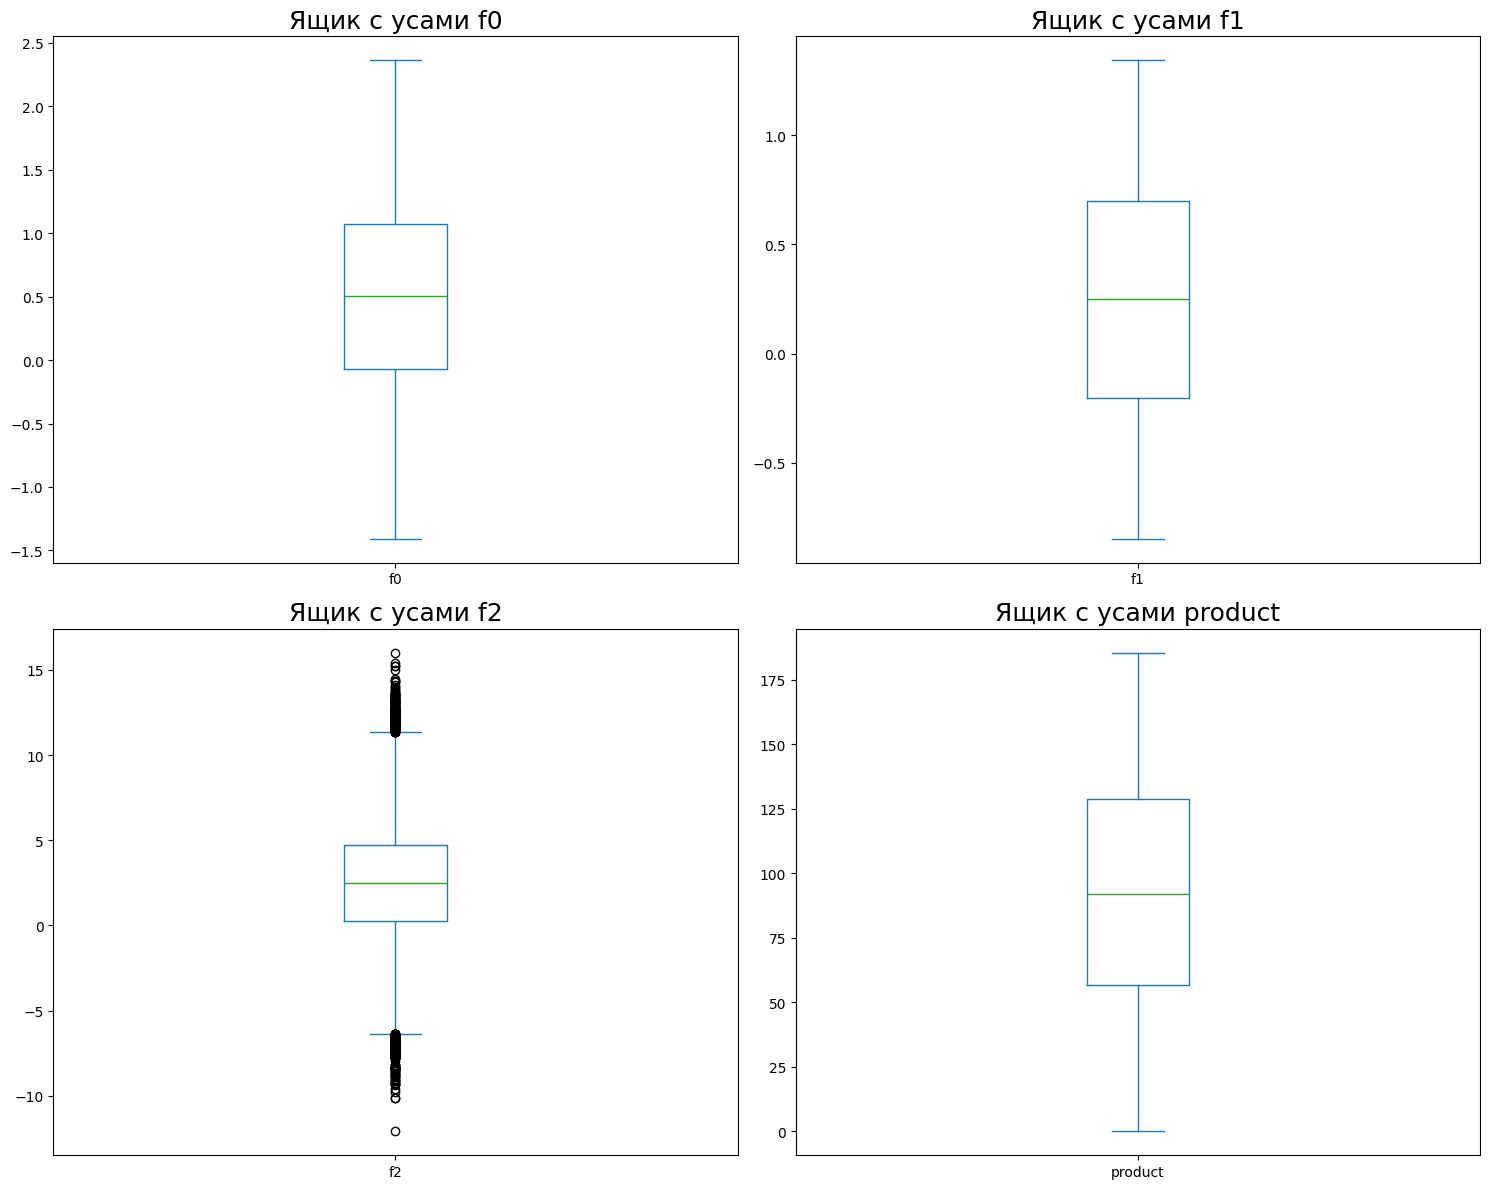

In [27]:
# строим боксплоты
print_boxes(df0)

Видим выбросы в f2, разберем их подробнее после того, как посмотрим на все датасеты

#### df1

In [28]:
df1.describe()

,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.141296,-4.796579,2.494541,68.825000
std,8.965932,5.119872,1.703572,45.944423
min,-31.609576,-26.358598,-0.018144,0.000000
25%,-6.298551,-8.267985,1.000021,26.953261
50%,1.153055,-4.813172,2.011479,57.085625
75%,8.621015,-1.332816,3.999904,107.813044
max,29.421755,18.734063,5.019721,137.945408


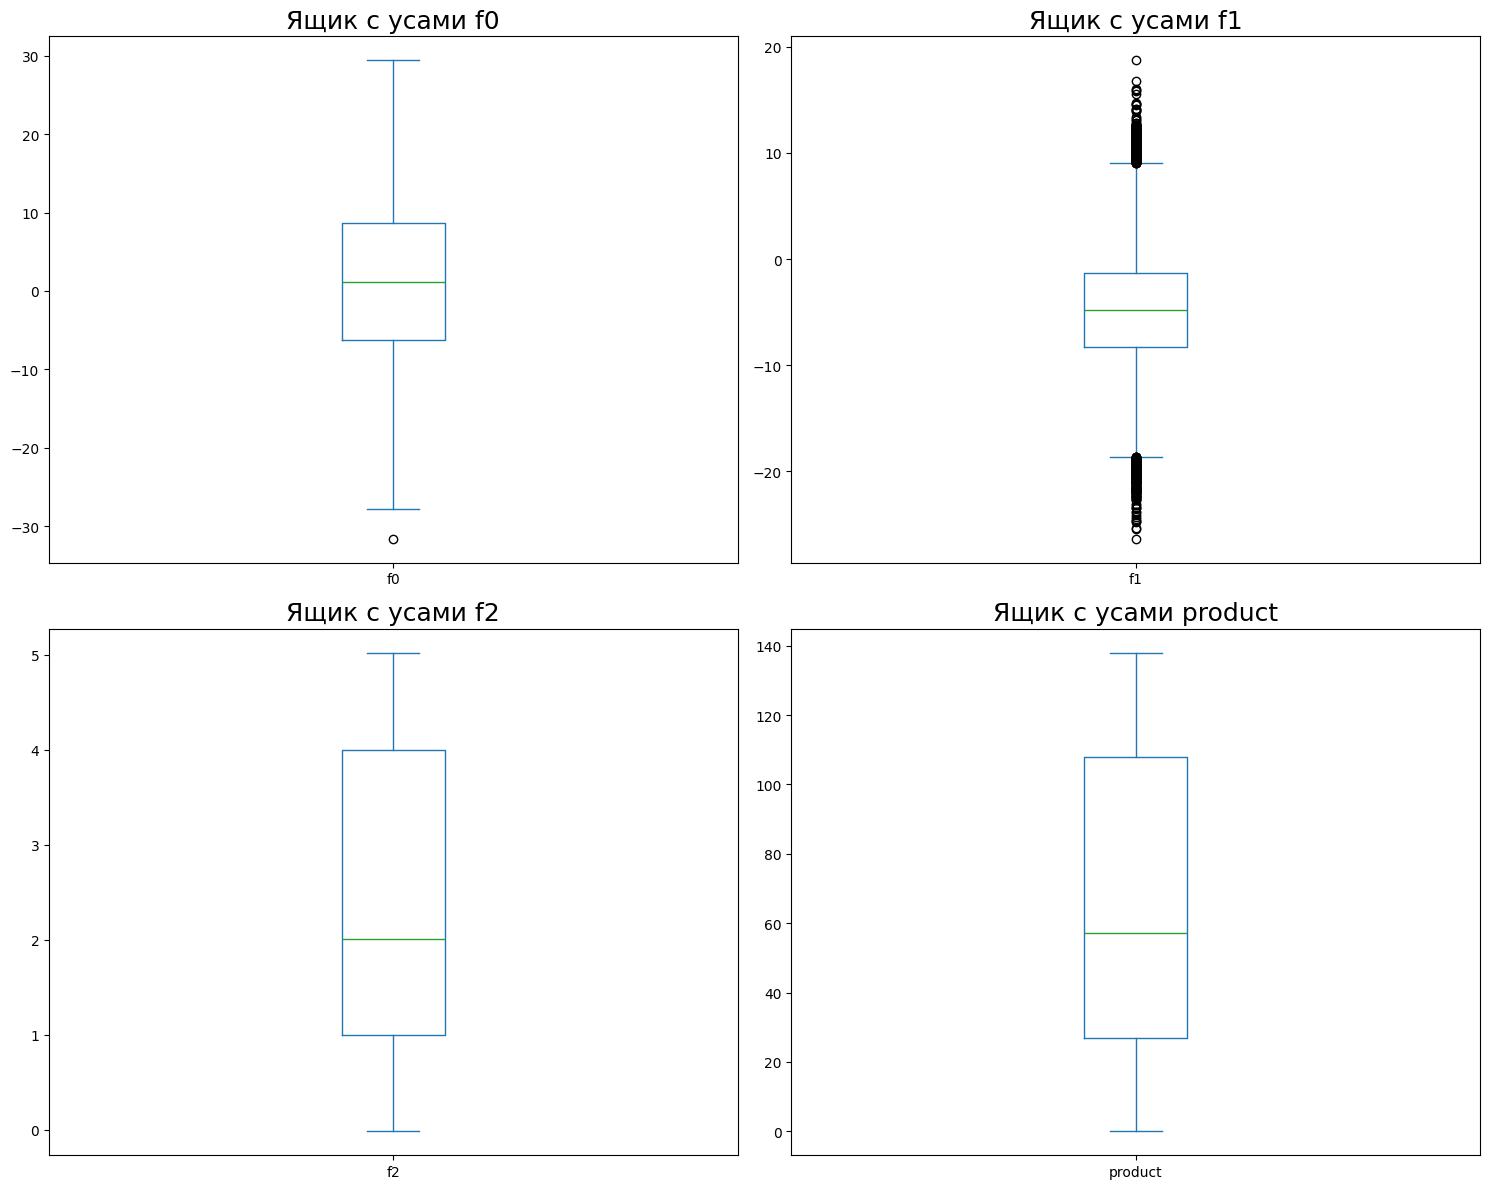

In [29]:
# строим боксплоты
print_boxes(df1)

Видим выбросы в f0 и f1, разберем их подробнее после того, как посмотрим на все датасеты

#### df2

In [30]:
df2.describe()

,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.002023,-0.002081,2.495128,95.000000
std,1.732045,1.730417,3.473445,44.749921
min,-8.760004,-7.084020,-11.970335,0.000000
25%,-1.162288,-1.174820,0.130359,59.450441
50%,0.009424,-0.009482,2.484236,94.925613
75%,1.158535,1.163678,4.858794,130.595027
max,7.238262,7.844801,16.739402,190.029838


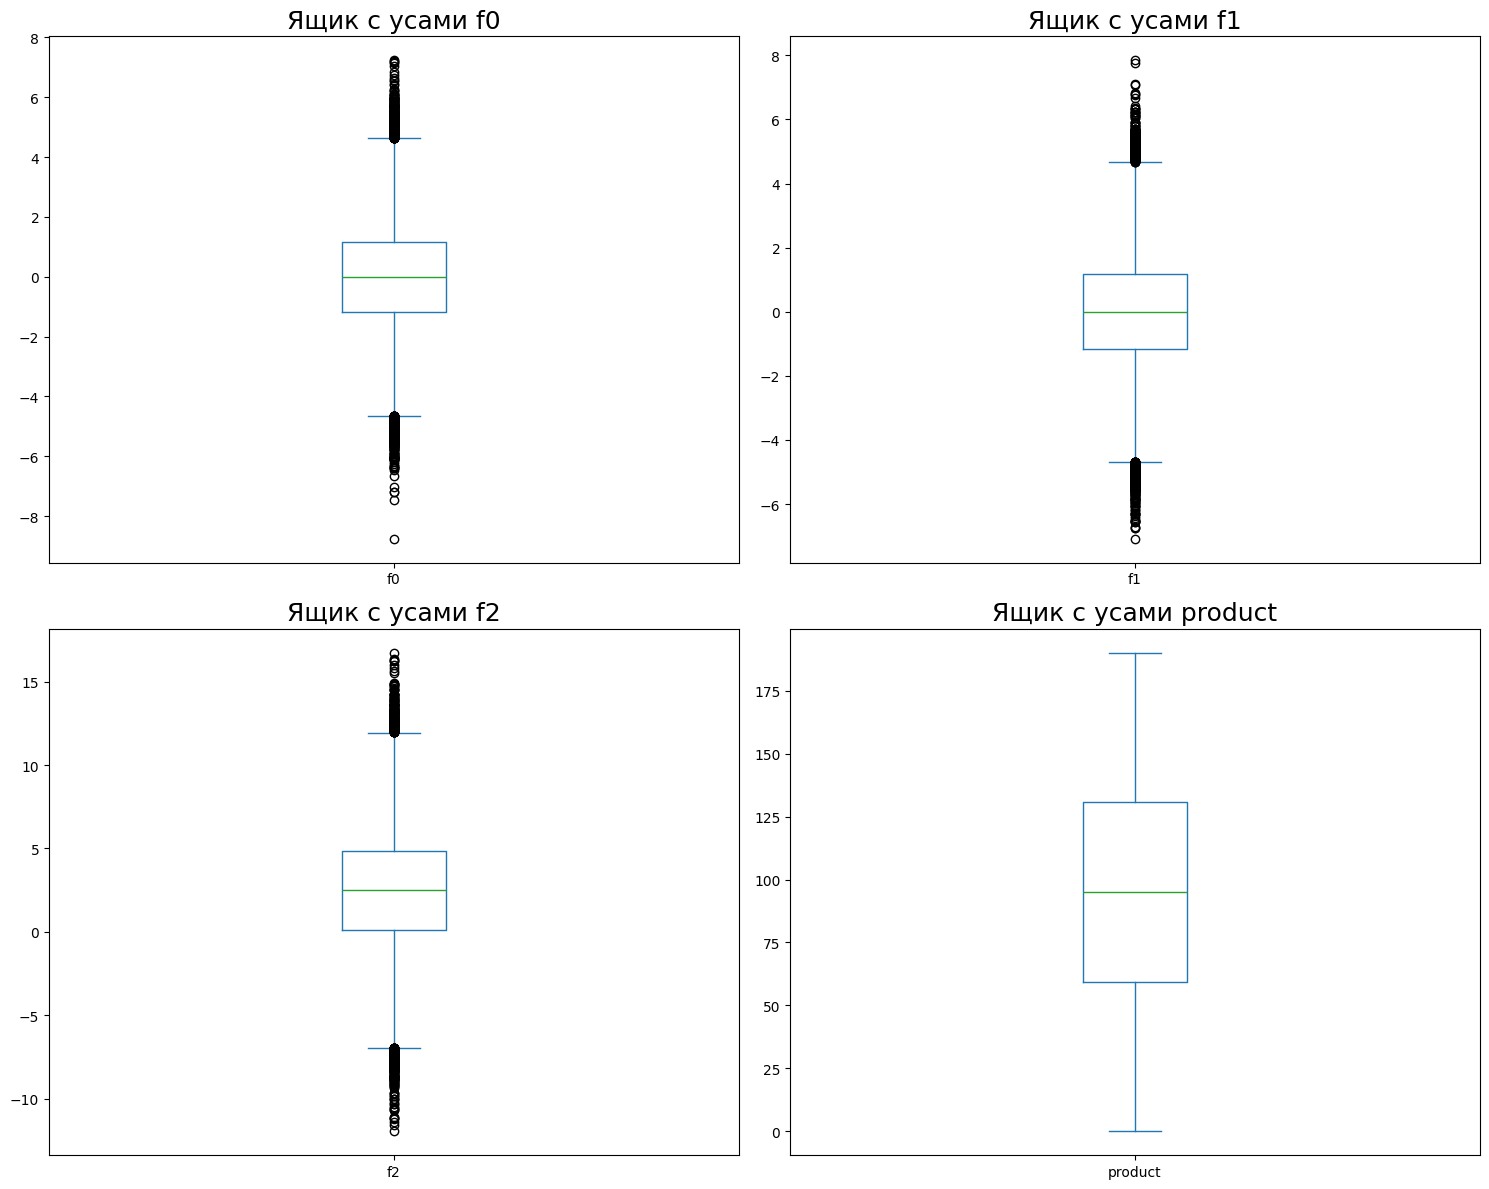

In [31]:
# строим боксплоты
print_boxes(df2)

Видим выбросы в f0, f1 и f2, разберем их ниже

Посмотрим на процент выбросов в обозначенных датасетах

In [32]:
print(f"Процент выбросов в f2 df0: {outlier_pct(df0, 'f2')}%")
print(f"Процент выбросов в f0 df1: {outlier_pct(df1, 'f0')}%")
print(f"Процент выбросов в f1 df1: {outlier_pct(df1, 'f1')}%")
print(f"Процент выбросов в f0 df2: {outlier_pct(df2, 'f0')}%")
print(f"Процент выбросов в f1 df2: {outlier_pct(df2, 'f1')}%")
print(f"Процент выбросов в f2 df2: {outlier_pct(df2, 'f2')}%")

Процент выбросов в f2 df0: 0.506%
Процент выбросов в f0 df1: 0.001%
Процент выбросов в f1 df1: 0.636%
Процент выбросов в f0 df2: 0.733%
Процент выбросов в f1 df2: 0.6839999999999999%
Процент выбросов в f2 df2: 0.584%


Результаты говорят нам, что выбросы можно удалить: в каждом не больше 0,75%. Применим функцию remove_outliers

In [33]:
df0 = remove_outliers(df0, ['f2'])
df1 = remove_outliers(df1, ['f0', 'f1'])
df2 = remove_outliers(df2, ['f0', 'f1', 'f2'])

In [34]:
# check
display(df0.shape)
display(df1.shape)
display(df2.shape)

(99494, 5)

(99363, 5)

(98003, 5)

### Матрицы корреляции

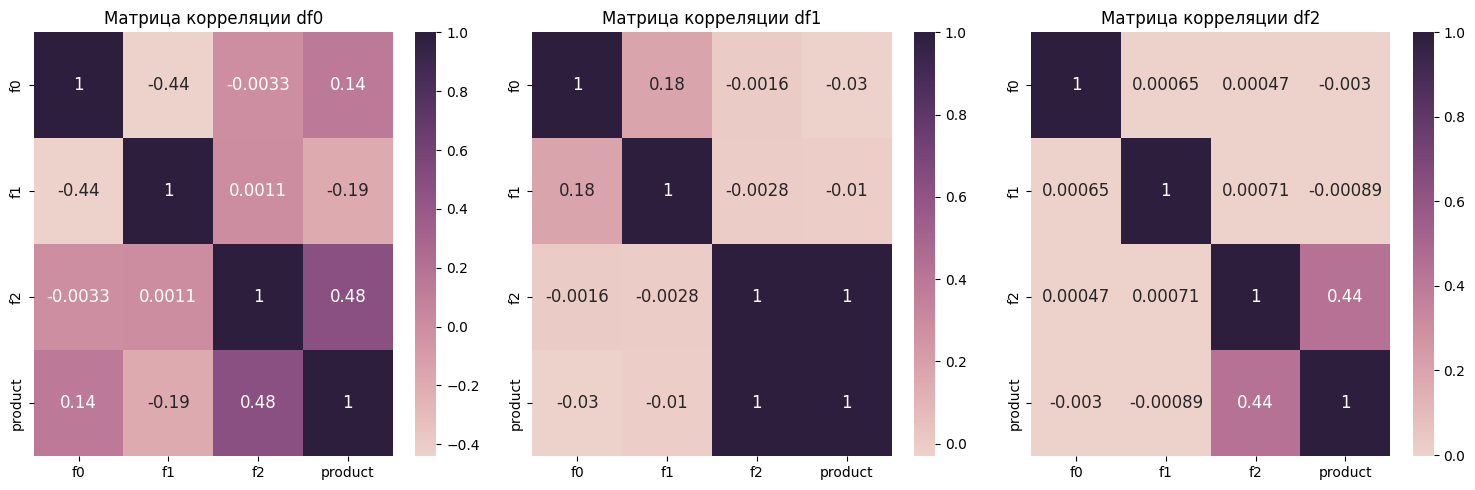

In [35]:
# построим для каждого датасета

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
titles = ["Матрица корреляции df0", "Матрица корреляции df1", "Матрица корреляции df2"]

for ax, df, title in zip(axs, [df0, df1, df2], titles):
    corr_matrix = df[df.columns[df.columns!= 'id']].corr()
    sns.heatmap(corr_matrix, annot=True, cmap=sns.cubehelix_palette(as_cmap=True), annot_kws={"size": 12}, ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()

- Налицо - очень сильная корреляция признака f2 с product во втором регионе (df1)
- Стоит также отметить умеренную корреляция между этими же признаками в первом и третьем регионах

Посмотрим на распределение признака product

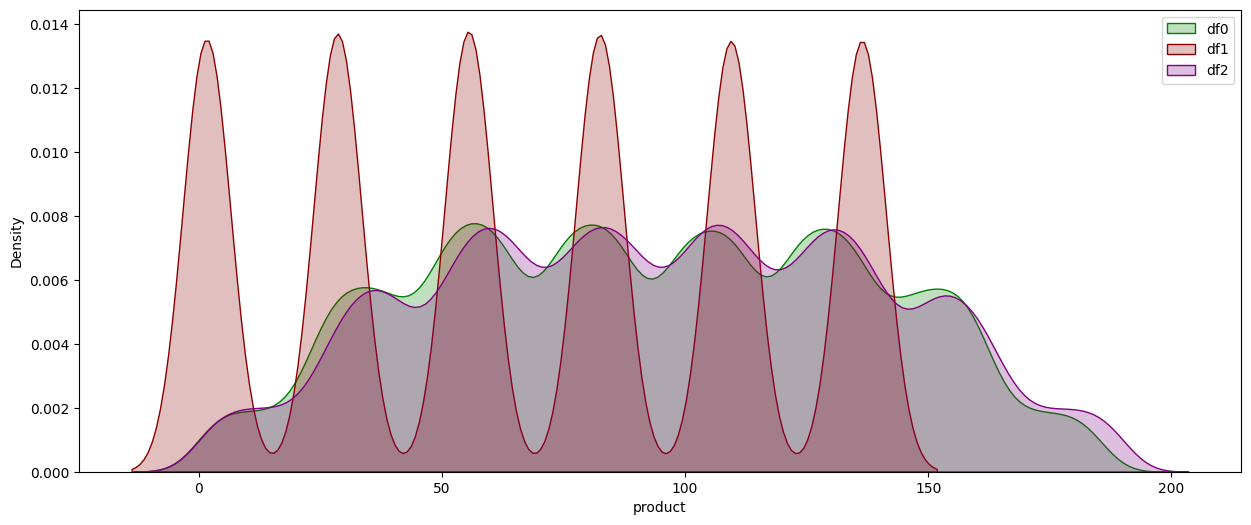

In [36]:
# Создаем фигуру и оси
fig, ax = plt.subplots(figsize=(15, 6))

# Рассчитываем KDE и строим его на графике
sns.kdeplot(df0['product'], ax=ax, fill=True, label='df0', color='green')
sns.kdeplot(df1['product'], ax=ax, fill=True, label='df1', color='darkred')
sns.kdeplot(df2['product'], ax=ax, fill=True, label='df2', color='purple')

# Добавляем легенду
ax.legend()

# Отображаем график
plt.show()

Бросается в глаза разница в распределении объёма запасов в скважине: в 1ом и 3ем регионе оно нормальное, а во втором - мультимодальное, присутствуют пики и провалы. Построим отдельно гистограмму по product для датасета df1

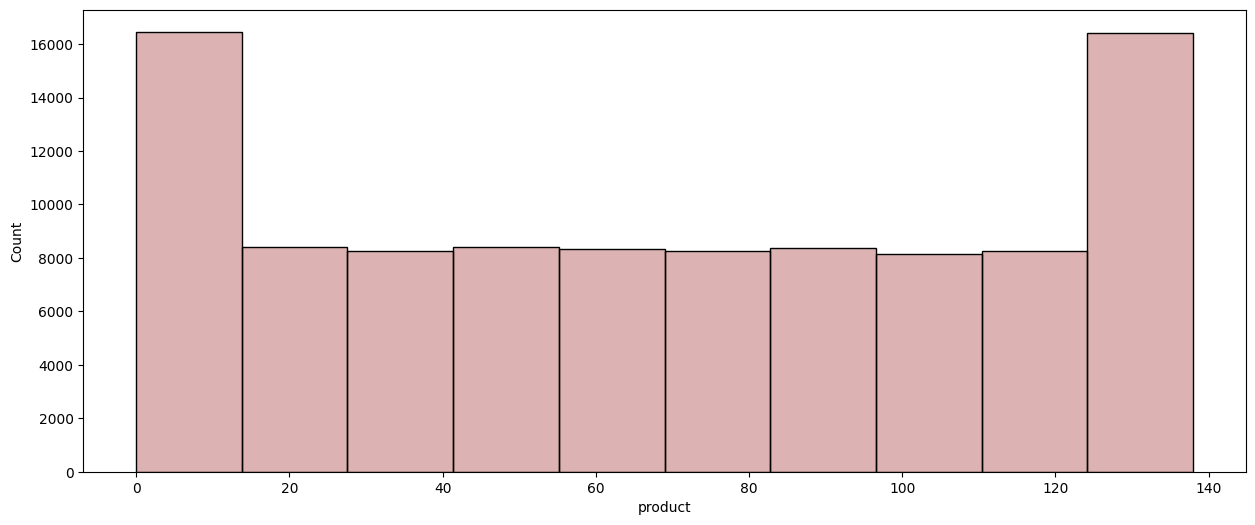

In [37]:
fig, ax = plt.subplots(figsize=(15, 6))
sns.histplot(data=df1, x='product', color='darkred', alpha=0.3, bins=10);

### Выводы по шагу 1
- Данные загружены и обработаны (пропуски и дубликаты отсутствуют);
- Матрицы корреляции показали очень сильную зависимость признаков f2 и product во втором регионе и умеренную в первом и третьем регионах;
- Также во втором регионе объёмы запасов в скважине очень сильно отличаются от первого и третьего регионов. Насколько это критично - узнаем дальше.

## Обучение и проверка модели

In [38]:
RANDOM_STATE = 42
TEST_SIZE = 0.25

### Регион 1

In [39]:
# разбиваем на входные признаки и целевой

X_0 = df0.drop(['product', 'id'], axis=1)
y_0 = df0['product']

# разбиваем на обучающую и валидационную выборки
X_train_0, X_test_0, y_train_0, y_test_0 = train_test_split(
    X_0, 
    y_0, 
    random_state=RANDOM_STATE,
    test_size=TEST_SIZE)

In [40]:
# масштабируем количественные признаки с помощью StandardScaler
scaler = StandardScaler()
X_train_scaled_0 = scaler.fit_transform(X_train_0)
X_test_scaled_0 = scaler.transform(X_test_0)

# инициализируем модель, сохраняем в переменную, обучаем
model_0 = LinearRegression()
model_0.fit(X_train_scaled_0, y_train_0)    
y_pred_0 = model_0.predict(X_test_scaled_0)
    
# считаем RMSE, выводим значение
rmse_0 = root_mean_squared_error(y_test_0, y_pred_0)

print(f'Средний запас предсказанного сырья {y_pred_0.mean()}')
print(f'RMSE первой модели {rmse_0}')

Средний запас предсказанного сырья 92.35054696467081
RMSE первой модели 37.81510477863427


### Регион 2

In [41]:
# разбиваем на входные признаки и целевой

X_1 = df1.drop(['product', 'id'], axis=1)
y_1 = df1['product']

# разбиваем на обучающую и валидационную выборки
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(
    X_1, 
    y_1, 
    random_state=RANDOM_STATE,
    test_size=TEST_SIZE)

In [42]:
# масштабируем количественные признаки с помощью StandardScaler
scaler = StandardScaler()
X_train_scaled_1 = scaler.fit_transform(X_train_1)
X_test_scaled_1 = scaler.transform(X_test_1)

# инициализируем модель, сохраняем в переменную, обучаем
model_1 = LinearRegression()
model_1.fit(X_train_scaled_1, y_train_1)
y_pred_1 = model_1.predict(X_test_scaled_1)
    
# считаем RMSE, выводим значение
rmse_1 = root_mean_squared_error(y_test_1, y_pred_1)

print(f'Средний запас предсказанного сырья {y_pred_1.mean()}')
print(f'RMSE второй модели {rmse_1}')

Средний запас предсказанного сырья 68.96189897916469
RMSE второй модели 0.8880473538662839


### Регион 3

In [43]:
# разбиваем на входные признаки и целевой

X_2 = df2.drop(['product', 'id'], axis=1)
y_2 = df2['product']

# разбиваем на обучающую и валидационную выборки
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_2,
    y_2,
    random_state=RANDOM_STATE,
    test_size=TEST_SIZE)

In [44]:
# масштабируем количественные признаки с помощью StandardScaler
scaler = StandardScaler()
X_train_scaled_2 = scaler.fit_transform(X_train_2)
X_test_scaled_2 = scaler.transform(X_test_2)

# инициализируем модель, сохраняем в переменную, обучаем
model_2 = LinearRegression()
model_2.fit(X_train_scaled_2, y_train_2)
y_pred_2 = model_2.predict(X_test_scaled_2)
    
# считаем RMSE, выводим значение
rmse_2 = root_mean_squared_error(y_test_2, y_pred_2)

print(f'Средний запас предсказанного сырья {y_pred_2.mean()}')
print(f'RMSE третьей модели {rmse_2}')

Средний запас предсказанного сырья 94.95178110761829
RMSE третьей модели 40.12959008344122


<div class='alert alert-warning'>⚠️ Все верно. А вот в таких случаях рекомендую в будущем однотипные действия (разбиение на выборки, шкалирование, построение регрессии, вывод метрик) объединять в функции, чтобы избежать описок и сделать код компактнее.  Кстати, шкалирование для класса LinearRegression можно не делать, так как это реализовано по умолчанию.

</div>

In [45]:
# сохраним данные в виде таблицы

pred_data = {
    'Средний запас предсказанного сырья': [
        y_pred_0.mean().round(4),
        y_pred_1.mean().round(4),
        y_pred_2.mean().round(4)
    ],
    'RMSE модели': [
        round(rmse_0, 4),
        round(rmse_1, 4),
        round(rmse_2, 4),
    ]
}

reg_metrics = pd.DataFrame(pred_data, index=['Регион 1','Регион 2', 'Регион 3'])

### Выводы по шагу 2

In [46]:
reg_metrics

,Средний запас предсказанного сырья,RMSE модели
Регион 1,92.3505,37.8151
Регион 2,68.9619,0.8880
Регион 3,94.9518,40.1296


- Разбили данные на обучающую и валидационную выборки в соотношении 75:25, обучили модель;
- Сделали предсказания и вывели на экран средний запас предсказанного сырья и RMSE модели в виде таблицы;
- Регион 3 лидирует по предсказанных запасам, а Регион 2 - по RMSE;
- Примечательно, что в Регионе 2 RMSE практически равна 0. Возможная причина: очень сильная корреляция признака f2 с product.

## Подготовка к расчёту прибыли

Основные вводные:

- При разведке региона исследуют 500 точек, из которых нужно отобрать 200 лучших для разработки;
- Бюджет на разработку скважин в регионе — 10 млрд рублей.
- Один баррель сырья приносит 450 рублей дохода. Доход с каждой единицы продукта составляет 450 тыс. рублей, поскольку объём указан в тысячах баррелей;
- После оценки рисков нужно оставить лишь те регионы, в которых вероятность убытков меньше 2.5%

In [47]:
# переменные

LOCATIONS_TOTAL = 500
LOCATIONS_BEST = 200
BUDGET = 10_000_000_000
INCOME_PRODUCT = 450_000
LOSS_PROB = 0.025

Рассчитаем достаточный объём сырья для безубыточной разработки новой скважины и сравним его со средним запасом в каждом регионе. 

In [48]:
break_even_point = round(BUDGET / INCOME_PRODUCT / LOCATIONS_BEST, 4)
print(f'Объём сырья, достаточный для безубыточной разработки новой скважины, равен {break_even_point} тыс. баррелей')

Объём сырья, достаточный для безубыточной разработки новой скважины, равен 111.1111 тыс. баррелей


In [49]:
# сохраним данные в виде таблицы

crude_data = {
    'Средний запас сырья': [
        df0['product'].mean().round(4),
        df1['product'].mean().round(4),
        df2['product'].mean().round(4)
    ],
    'Точка безубыточности': [
        break_even_point,
        break_even_point,
        break_even_point,
    ],
    'Разница': [
        round(break_even_point - df0['product'].mean(), 4),
        round(break_even_point - df1['product'].mean(), 4),
        round(break_even_point - df2['product'].mean(), 4)
    ]
}

crude = pd.DataFrame(crude_data, index=['Регион 1','Регион 2', 'Регион 3'])

In [50]:
crude

,Средний запас сырья,Точка безубыточности,Разница
Регион 1,92.5007,111.1111,18.6104
Регион 2,68.8095,111.1111,42.3016
Регион 3,94.7851,111.1111,16.3260


### Выводы по шагу 3:
- Средний запас сырья во всех регионах значительно меньше, чем нужно для безубыточной разработки новой скважины (111.1111);
- Во 2-ом регионе разница достигает значения больше х1,5, при этом модель дает практически идеальные прогнозы (чем ниже значение RMSE, тем точнее модель прогнозирует значения).

## Расчёт прибыли

### Скважины с max значениями предсказаний. Функция

**Подготовка**

Сбросим индексы у таргета и предсказания для удобства

In [51]:
y_test_0 = y_test_0.reset_index(drop=True)
y_pred_0 = pd.Series(y_pred_0)

y_test_1 = y_test_1.reset_index(drop=True)
y_pred_1 = pd.Series(y_pred_1)

y_test_2 = y_test_2.reset_index(drop=True)
y_pred_2 = pd.Series(y_pred_2)

**Функция для расчёта прибыли по выбранным скважинам и предсказаниям модели**

In [52]:
def revenue_print(target, probabilities, count, region_no):
    probs_sorted = probabilities.sort_values(ascending=False)
    selected = target[probs_sorted.index][:count]
    top_200 = selected.sum()
    predict_profit = top_200 * INCOME_PRODUCT - BUDGET
    
    print(f'Прогноз объема сырья в лучших {count} скважинах в Регионе {region_no}: {round(top_200, 3)} тыс. баррелей')
    print(f'Потенциальная прибыль в Регионе {region_no}: {round(predict_profit / 1000000, 3)} млн. рублей')

### Расчеты прибыли

In [53]:
revenue_print(y_test_0, y_pred_0, LOCATIONS_BEST, 1)
print('---')
revenue_print(y_test_1, y_pred_1, LOCATIONS_BEST, 2)
print('---')
revenue_print(y_test_2, y_pred_2, LOCATIONS_BEST, 3)

Прогноз объема сырья в лучших 200 скважинах в Регионе 1: 29449.689 тыс. баррелей
Потенциальная прибыль в Регионе 1: 3252.36 млн. рублей
---
Прогноз объема сырья в лучших 200 скважинах в Регионе 2: 27589.082 тыс. баррелей
Потенциальная прибыль в Регионе 2: 2415.087 млн. рублей
---
Прогноз объема сырья в лучших 200 скважинах в Регионе 3: 27522.921 тыс. баррелей
Потенциальная прибыль в Регионе 3: 2385.314 млн. рублей


### Выводы по шагу 4:
- Самый большой объёма сырья прогнозируется в Регионе 1
- Потенцильная прибыль везде наблюдается положительная, лидирует также Регион 1

## Риски и прибыль для каждого региона

In [54]:
def revenue(target, probabilities, count):
    probs_sorted = probabilities.sort_values(ascending=False)
    selected = target[probs_sorted.index][:count]
    return selected.sum() * INCOME_PRODUCT - BUDGET

In [55]:

def boostrap(target, probabilities, n, count, region_no):
    state = np.random.RandomState(12345)
    values = []
    for i in range(1000):
        target_subsample = target.sample(n, replace=True, random_state=state)
        probs_subsample = probabilities[target_subsample.index]
        revenue_value = revenue(target_subsample.reset_index(drop=True), probs_subsample.reset_index(drop=True), count)
        values.append(revenue_value)
        
    values = pd.Series(values)
    values_mean = values.mean()
    
    lower = values.quantile(0.025)
    upper = values.quantile(0.975)
    m = 1000000
    
    neg_vals = sum(value < 0 for value in values)
    loss_risk = neg_vals / 1000
    
    print(f'Средняя прибыль в Регионе {region_no}: {round(values_mean/m, 4)} млн. рублей')
    print(f'95%-й доверительный интервал в Регионе {region_no}: от {round(lower/m, 4)} млн. до {round(upper/m, 4)} млн.')
    print(f'Вероятность убытков в Регионе {region_no}: {loss_risk * 100:.2f}%')
    if loss_risk < LOSS_PROB:
        print('\033[32mРегион соответствует заявленным требованиям\033[0m')
    else:
        print('\033[31mРегион НЕ соответствует заявленным требованиям\033[0m')

### Данные по регионам

In [56]:
boostrap(y_test_0, y_pred_0, LOCATIONS_TOTAL, LOCATIONS_BEST, 1)

Средняя прибыль в Регионе 1: 393.0863 млн. рублей
95%-й доверительный интервал в Регионе 1: от -146.3928 млн. до 898.5263 млн.
Вероятность убытков в Регионе 1: 6.60%
Регион НЕ соответствует заявленным требованиям


In [57]:
boostrap(y_test_1, y_pred_1, LOCATIONS_TOTAL, LOCATIONS_BEST, 2)

Средняя прибыль в Регионе 2: 455.7727 млн. рублей
95%-й доверительный интервал в Регионе 2: от 55.7662 млн. до 851.7654 млн.
Вероятность убытков в Регионе 2: 1.50%
Регион соответствует заявленным требованиям


In [58]:
boostrap(y_test_2, y_pred_2, LOCATIONS_TOTAL, LOCATIONS_BEST, 3)

Средняя прибыль в Регионе 3: 375.5367 млн. рублей
95%-й доверительный интервал в Регионе 3: от -136.9444 млн. до 857.0349 млн.
Вероятность убытков в Регионе 3: 7.70%
Регион НЕ соответствует заявленным требованиям


<div class='alert alert-warning'>⚠️ Как считаешь, не лучше в функцию прибыли передавать аргументы со сброшенными индексами  (target_subsample.reset_index(drop=True), probs_subsample.reset_index(drop=True))? Это обеспечит недопущение попадания искусственных повторов при подсчете прибыли, в выборку из 200 точек (читай <a href='https://zen.yandex.ru/media/id/5ee6f73b7cadb75a66e4c7e3/lovushka-semlirovaniia-privodiascaia-k-razmnojeniiu-povtornyh-indeksov-62d25c205f37c21646e36711'> тут </a>).

</div>

### Выводы по шагу 5:

- Лучший регион по средней прибыли - Регион 2 (514.3808 млн. рублей);
- Более того, Регион 2 - единственный регион, который соответствует требованию "нужно оставить лишь те регионы, в которых вероятность убытков меньше 2.5%"

## Выводы:

Основной задачей было построить модель для определения региона, где добыча принесёт наибольшую прибыль. Необходимо было проанализировать возможную прибыль и риски.

В ходе работы было сделано следующее:
- Изучили датасеты, провели исследовательский анализ - не нашли дубликатов, пропусков также обнаружено не было. Боксплоты показали нам выбросы, которые мы удалили, так как они занимали очень небольшюу часть. Матрица корреляции по второму региону выдала нам очень сильную корреляцию между признаками f2 и product. В первом и третьем региону эти признаки тоже коррелируют, но в гораздо меньшей степени;
- Обучили модель и сделали предсказания по среднему запасу сырья, посчитали RMSE моделей, получили любопытный факт по Региону 2: модель дает практически идеальные прогнозы (0.89);
- Завели отдельные переменные для удобства расчетов, посчитали объём сырья, достаточный для безубыточной разработки новой скважины, сравнили его с запасами;
- Сделали прогноз по объему сырья в топ-200 скважинах в каждом Регионе, посчитали потенциальную прибыль в Регионах, подготовили для этого функцию;
- Нашли среднюю прибыль в Регионах, 95%-й доверительный интервал и расчитали вероятность убытков

---

**Что касается предложений, однозначная рекомендация - обратить внимание на Регион 2**: тут и самая высокая средняя прибыль, и "приятный" доверительный интервал, и вероятность убытков минимальная. Более того, это единственный регион, который соответствует заявленным условиям. Даже несмотря на наименьший средний запас сырья в скважинах

<div class='alert alert-info'>🏁 Отличная работа, Александр!  Качественно исследовал и подготовил признаки, корректно выполнил разделение на выборки и построил регрессию, посчитал целевые метрики и определил оптимальный регион с точки зрения прибыли и рисков убытков. Осталось дать обратную связь по выделенным ячейкам (при необходимости).

</div>

## Чек-лист готовности проекта

Поставьте 'x' в выполненных пунктах. Далее нажмите Shift+Enter.

- [x]  Jupyter Notebook открыт
- [x]  Весь код выполняется без ошибок
- [x]  Ячейки с кодом расположены в порядке исполнения
- [x]  Выполнен шаг 1: данные подготовлены
- [x]  Выполнен шаг 2: модели обучены и проверены
    - [x]  Данные корректно разбиты на обучающую и валидационную выборки
    - [x]  Модели обучены, предсказания сделаны
    - [x]  Предсказания и правильные ответы на валидационной выборке сохранены
    - [x]  На экране напечатаны результаты
    - [x]  Сделаны выводы
- [x]  Выполнен шаг 3: проведена подготовка к расчёту прибыли
    - [x]  Для всех ключевых значений созданы константы Python
    - [x]  Посчитано минимальное среднее количество продукта в месторождениях региона, достаточное для разработки
    - [x]  По предыдущему пункту сделаны выводы
    - [x]  Написана функция расчёта прибыли
- [x]  Выполнен шаг 4: посчитаны риски и прибыль
    - [x]  Проведена процедура *Bootstrap*
    - [x]  Все параметры бутстрепа соответствуют условию
    - [x]  Найдены все нужные величины
    - [x]  Предложен регион для разработки месторождения
    - [x]  Выбор региона обоснован